# 00 – Baseline: pillar CenterNet + data exploration
First baseline for the MaCVi 2027 Diver3D challenge: dataset download, `FORMAT.md`, quaternion-order check, pose (tilt) statistics with plots, and a BEV pillar CenterNet trained for 3 epochs.

**Result (val, every 10th frame, official scorer):** SDS 0.378 · mAP3D 0.112 · APBEV@0.35 0.59 · AOE3D 45.1°

Divers are found well from above (APBEV 0.59), but the 3D boxes are poor because the pillar encoder throws away vertical structure. This motivated the voxel model in notebook 02.

In [1]:
!pip -q install gdown
!gdown --folder "https://drive.google.com/drive/folders/16HHHfCWM_p8RIvHQkQ38PMnZJNXzgXdU" -O /content/dl
!ls -lh /content/dl

Retrieving folder contents
Processing file 1MxBRohKXmK5ewLgNe773_SwmIqvTis_G diver3d_v2.zip
Processing file 1xYQCMGKUypaXu9aDUCKZK0rId2BjtTSJ diver3d_v2.zip.sha256
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From (original): https://drive.google.com/uc?id=1MxBRohKXmK5ewLgNe773_SwmIqvTis_G
From (redirected): https://drive.google.com/uc?id=1MxBRohKXmK5ewLgNe773_SwmIqvTis_G&confirm=t&uuid=ae1bd360-1bb5-4c2c-be93-ff5cbf9f95aa
To: /content/dl/diver3d_v2.zip
100%|██████████████████████████████████████| 3.45G/3.45G [00:41<00:00, 82.4MB/s]
Downloading...
From: https://drive.google.com/uc?id=1xYQCMGKUypaXu9aDUCKZK0rId2BjtTSJ
To: /content/dl/diver3d_v2.zip.sha256
100%|█████████████████████████████████████████| 81.0/81.0 [00:00<00:00, 403kB/s]
Download completed
total 3.3G
-rw-r--r-- 1 root root 3.3G Oct  2 17:28 diver3d_v2.zip
-rw-r--r-- 1 root root   81 Oct  2 17:24 diver3d_v2.zip.sha256


In [4]:
import os
ROOT = "/content/diver3d/diver3d_v2"
print(sorted(os.listdir(ROOT)))
print("annotations:", sorted(os.listdir(f"{ROOT}/annotations")))
print("tools:", sorted(os.listdir(f"{ROOT}/tools")))

['CHECKSUMS.sha256', 'FORMAT.md', 'LICENSE.txt', 'METRICS.md', 'README.md', 'annotations', 'scenes', 'splits.json', 'tools']
annotations: ['gt_train.json', 'gt_val.json', 'test_tokens.txt']
tools: ['__pycache__', 'diver3d.py', 'diver3d_eval.py', 'validate_submission.py']


In [5]:
!pip -q install gdown numpy scipy matplotlib tqdm open3d
import torch
print("torch", torch.__version__, "| cuda:", torch.cuda.is_available())

torch 2.11.0+cu128 | cuda: True


In [7]:
import sys, os, platform
print(sys.version)
print(platform.platform())
!nvidia-smi
!df -h . | tail -1

3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Linux-6.18.55+-x86_64-with-glibc2.39
Sat Oct 24 11:42:27 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8             10W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |         

In [8]:
%cd dl
!echo "73bcee1251f5f12932859e4ef421e646c569124211628633989d4303aa5f89cb  diver3d_v2.zip" | sha256sum -c
%cd ..

/content/dl
diver3d_v2.zip: OK
/content


In [14]:
import numpy as np, glob, os
ROOT = "/content/diver3d/diver3d_v2"

def load_bin(path):
    raw = np.fromfile(path, dtype=np.float32)
    assert raw.size % 4 == 0, f"{path}: {raw.size} floats not divisible by 4"
    return raw.reshape(-1, 4)

pts = load_bin(f"{ROOT}/scenes/scene_0000/sonar/frame_000000.bin")
print(pts.shape, pts.dtype)
print("min", pts.min(0))
print("max", pts.max(0))
print("any NaN:", np.isnan(pts).any())

(8154, 4) float32
min [ 4.2625257e-01 -5.9177966e+00 -2.9914236e+00  2.6240502e-04]
max [14.454448   5.607097   2.9595888  1.       ]
any NaN: False


In [15]:
import random
files = glob.glob(f"{ROOT}/scenes/*/sonar/*.bin")
print(len(files), "frames")
Ns, mins, maxs = [], [], []
for f in random.sample(files, 300):
    p = load_bin(f)
    Ns.append(len(p)); mins.append(p.min(0)); maxs.append(p.max(0))
print("N range:", min(Ns), max(Ns))
print("global min:", np.min(mins, 0))
print("global max:", np.max(maxs, 0))

37010 frames
N range: 2304 10358
global min: [ 1.6490708e-01 -1.1042635e+01 -5.2541451e+00  5.5907317e-06]
global max: [15.998896  11.128879   5.4797535  1.       ]


In [16]:
!cat {ROOT}/FORMAT.md

# Diver3D — data and submission format

## 1. Coordinate frame

All geometry is expressed in the **sonar frame**: right-handed, metres.

| axis | direction |
|------|-----------|
| `x`  | forward, along the sonar boresight |
| `y`  | left |
| `z`  | up |

Observed extent of the released point clouds:
`x ∈ [0.13, 16.02] m`, `y ∈ [−11.33, 11.31] m`, `z ∈ [−5.48, 5.48] m`.

The baseline crops to `[0, 12] × [−5, 5] × [−2.5, 2.5] m`, which retains 89.1 % of
points and 99.9 % of annotated divers. **Participants are free to use any crop**;
evaluation is over all annotated instances, so a tighter crop costs recall.

## 2. Point clouds

`sonar/frame_%06d.bin` — a raw little-endian `float32` array of shape `(N, 4)`:

```python
pts = np.fromfile(path, dtype=np.float32).reshape(-1, 4)   # x, y, z, intensity
```

`intensity` is the normalised acoustic return in `[0, 1]`. `N` ranges from 428 to
11,965 per frame and is approximately normally distributed.

## 3. Box convention

This is the part that m

In [17]:
import json
gt = json.load(open(f"{ROOT}/annotations/gt_val.json"))
print(type(gt), (list(gt.keys())[:10] if isinstance(gt, dict) else len(gt)))
print(json.dumps(gt, indent=1)[:2500])
print()
sp = json.load(open(f"{ROOT}/splits.json"))
print(type(sp), (list(sp.keys()) if isinstance(sp, dict) else len(sp)))
print(str(sp)[:600])
!head -3 {ROOT}/annotations/test_tokens.txt

<class 'dict'> ['split', 'results']
{
 "split": "val",
 "results": {
  "scene_0000/000000": [
   {
    "center": [
     2.11066582,
     -1.06992543,
     0.0731936
    ],
    "dimensions": [
     0.84,
     1.03,
     1.56
    ],
    "quaternion": [
     0.23322318,
     -0.04241418,
     0.01018274,
     0.97144444
    ],
    "instance_id": 1
   }
  ],
  "scene_0000/000001": [
   {
    "center": [
     2.08147192,
     -1.19053733,
     0.2421979
    ],
    "dimensions": [
     0.86908648,
     1.25695495,
     1.45808029
    ],
    "quaternion": [
     0.32453017,
     0.0,
     0.0,
     0.94587534
    ],
    "instance_id": 1
   }
  ],
  "scene_0000/000002": [
   {
    "center": [
     2.06844592,
     -1.19017947,
     0.24722177
    ],
    "dimensions": [
     0.86731889,
     1.25106298,
     1.45436579
    ],
    "quaternion": [
     0.32252064,
     0.0,
     0.0,
     0.94656243
    ],
    "instance_id": 1
   }
  ],
  "scene_0000/000003": [
   {
    "center": [
     2.0806236

In [18]:
import json, numpy as np, os
ROOT = "/content/diver3d/diver3d_v2"

def load_bin(path):
    return np.fromfile(path, dtype=np.float32).reshape(-1, 4)

def frame_path(token):
    scene, frame = token.split("/")
    return f"{ROOT}/scenes/{scene}/sonar/frame_{int(frame):06d}.bin"

def quat_to_rotmat(q):  # q = (w, x, y, z), copied from FORMAT.md
    w, x, y, z = np.asarray(q, float) / np.linalg.norm(q)
    return np.array([
        [1-2*(y*y+z*z),   2*(x*y-w*z),   2*(x*z+w*y)],
        [  2*(x*y+w*z), 1-2*(x*x+z*z),   2*(y*z-w*x)],
        [  2*(x*z-w*y),   2*(y*z+w*x), 1-2*(x*x+y*y)],
    ])

gt_train = json.load(open(f"{ROOT}/annotations/gt_train.json"))["results"]
gt_val   = json.load(open(f"{ROOT}/annotations/gt_val.json"))["results"]
print(len(gt_train), "train frames |", len(gt_val), "val frames")
print("empty frames: train %.1f%%, val %.1f%%" % (
    100*np.mean([len(v)==0 for v in gt_train.values()]),
    100*np.mean([len(v)==0 for v in gt_val.values()])))

20861 train frames | 8037 val frames
empty frames: train 26.6%, val 25.9%


In [19]:
def tilt_deg(R):  # angle between sonar z and body up-axis ez = R[:, 2]
    return np.degrees(np.arccos(np.clip(R[2, 2], -1, 1)))

qs = np.array([b["quaternion"] for v in gt_train.values() for b in v])
print(len(qs), "train instances")

for name, order in [("wxyz (FORMAT.md)", [0,1,2,3]), ("xyzw (alternative)", [3,0,1,2])]:
    t = np.array([tilt_deg(quat_to_rotmat(q[order])) for q in qs])
    print(f"{name:20s} upright(<15): {100*np.mean(t<15):5.1f}%   "
          f"horizontal(75-105): {100*np.mean((t>75)&(t<105)):5.1f}%")
print("FORMAT.md reports    upright: 34.8%   horizontal: 30.7%  (over all splits)")

19482 train instances
wxyz (FORMAT.md)     upright(<15):  19.6%   horizontal(75-105):  40.8%
xyzw (alternative)   upright(<15):   4.5%   horizontal(75-105):  62.1%
FORMAT.md reports    upright: 34.8%   horizontal: 30.7%  (over all splits)


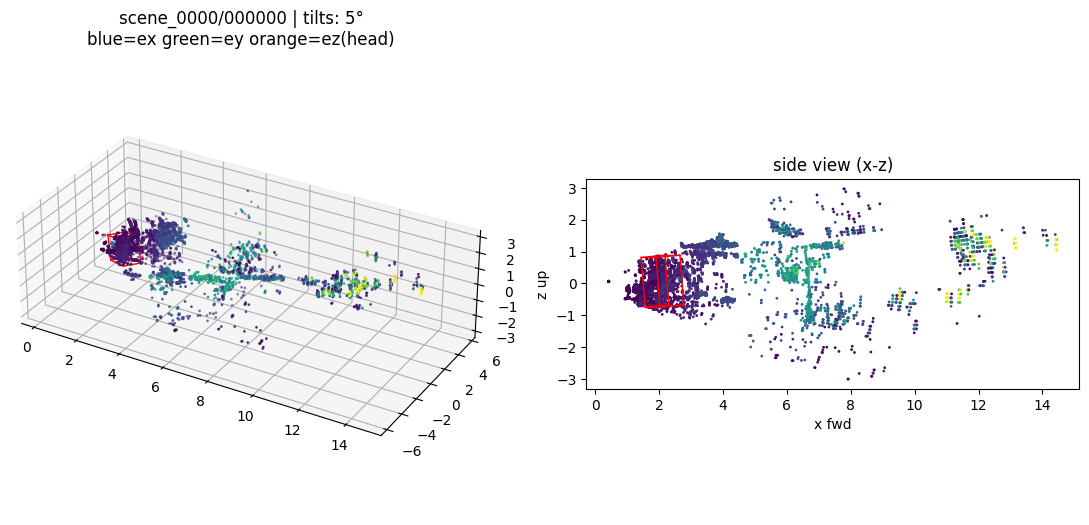

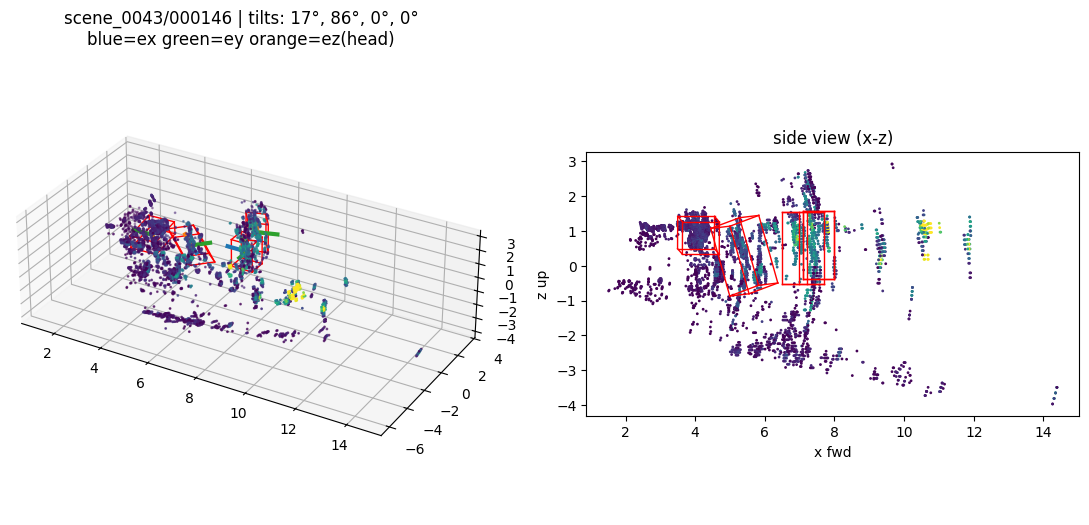

In [24]:
import matplotlib.pyplot as plt

def box_corners(c, d, R):
    s = np.array([[sx, sy, sz] for sx in (-1, 1) for sy in (-1, 1) for sz in (-1, 1)]) * 0.5
    return (s * np.asarray(d)) @ R.T + np.asarray(c)

EDGES = [(0,1),(2,3),(4,5),(6,7),(0,2),(1,3),(4,6),(5,7),(0,4),(1,5),(2,6),(3,7)]





def show(token, gt, order=(0,1,2,3)):
    pts = load_bin(frame_path(token))
    boxes = gt[token]
    fig = plt.figure(figsize=(14, 6))
    ax3 = fig.add_subplot(1, 2, 1, projection="3d")
    ax2 = fig.add_subplot(1, 2, 2)
    ax3.scatter(pts[:,0], pts[:,1], pts[:,2], c=pts[:,3], s=1, cmap="viridis")
    ax2.scatter(pts[:,0], pts[:,2], c=pts[:,3], s=1, cmap="viridis")
    for b in boxes:
        R = quat_to_rotmat(np.array(b["quaternion"])[list(order)])
        C = box_corners(b["center"], b["dimensions"], R)
        for i, j in EDGES:
            ax3.plot(*C[[i, j]].T, c="r", lw=1)
            ax2.plot(C[[i, j], 0], C[[i, j], 2], c="r", lw=1)
        c = np.array(b["center"])
        for k, col in enumerate(["tab:blue", "tab:green", "tab:orange"]):  # ex, ey, ez
            ax3.plot(*np.c_[c, c + 0.8*R[:, k]], c=col, lw=3)
        ax3.set_title(f"{token} | tilt {tilt_deg(R):.0f}° | blue=ex green=ey orange=ez(head)")
    # ax3.set_xlabel("x fwd"); ax3.set_ylabel("y left"); ax3.set_zlabel("z up")
    ax3.set_title(f"{token} | tilts: " + ", ".join(
    f"{tilt_deg(quat_to_rotmat(b['quaternion'])):.0f}°" for b in boxes)
    + "\nblue=ex green=ey orange=ez(head)")
    ax2.set_xlabel("x fwd"); ax2.set_ylabel("z up"); ax2.set_title("side view (x-z)")
    ax2.set_aspect("equal"); ax3.set_box_aspect((2, 1, 0.6))
    plt.show()

# one upright and one near-horizontal example
def first_with_tilt(gt, lo, hi):
    for tok, bs in gt.items():
        for b in bs:
            if lo < tilt_deg(quat_to_rotmat(b["quaternion"])) < hi:
                return tok

show(first_with_tilt(gt_val, 0, 15), gt_val)
show(first_with_tilt(gt_val, 75, 105), gt_val)

In [21]:
def tilt_stats(gt, order, fold=False):
    qs = np.array([b["quaternion"] for v in gt.values() for b in v])[:, order]
    t = np.array([tilt_deg(quat_to_rotmat(q)) for q in qs])
    if fold: t = np.minimum(t, 180 - t)   # treat upside-down as tilted from vertical
    return 100*np.mean(t < 15), 100*np.mean((t > 75) & (t < 105)), len(t)

for split, gt in [("train", gt_train), ("val", gt_val)]:
    for name, order in [("wxyz", [0,1,2,3]), ("xyzw", [3,0,1,2])]:
        for fold in (False, True):
            u, h, n = tilt_stats(gt, order, fold)
            print(f"{split:5s} {name} fold={str(fold):5s} n={n:5d}  upright {u:5.1f}%  horizontal {h:5.1f}%")

train wxyz fold=False n=19482  upright  19.6%  horizontal  40.8%
train wxyz fold=True  n=19482  upright  19.6%  horizontal  40.8%
train xyzw fold=False n=19482  upright   4.5%  horizontal  62.1%
train xyzw fold=True  n=19482  upright   5.7%  horizontal  62.1%
val   wxyz fold=False n= 7509  upright  52.1%  horizontal  15.2%
val   wxyz fold=True  n= 7509  upright  52.1%  horizontal  15.2%
val   xyzw fold=False n= 7509  upright   9.6%  horizontal  29.9%
val   xyzw fold=True  n= 7509  upright  11.7%  horizontal  29.9%


In [22]:
import random
random.seed(0)
inst = [(tok, b) for tok, bs in gt_train.items() for b in bs]
sample = random.sample(inst, 400)

def inside_count(pts, c, d, R):
    local = (pts[:, :3] - np.asarray(c)) @ R        # body-frame coords
    return int(np.all(np.abs(local) <= np.asarray(d) / 2, axis=1).sum())

a, b_ = [], []
for tok, b in sample:
    pts = load_bin(frame_path(tok))
    q = np.array(b["quaternion"])
    a.append(inside_count(pts, b["center"], b["dimensions"], quat_to_rotmat(q)))
    b_.append(inside_count(pts, b["center"], b["dimensions"], quat_to_rotmat(q[[3,0,1,2]])))
a, b_ = np.array(a), np.array(b_)
diff = a != b_
print(f"mean points inside: wxyz {a.mean():.0f}   xyzw {b_.mean():.0f}")
print(f"where the two differ ({diff.sum()} boxes): wxyz wins {np.mean(a[diff] > b_[diff])*100:.0f}%")

mean points inside: wxyz 895   xyzw 695
where the two differ (383 boxes): wxyz wins 93%


In [26]:
import json
gt_val = json.load(open(f"{ROOT}/annotations/gt_val.json"))["results"]
pred = {"results": {
    tok: [{"center": b["center"], "dimensions": b["dimensions"],
           "quaternion": b["quaternion"], "score": 1.0} for b in boxes]
    for tok, boxes in gt_val.items()}}
json.dump(pred, open("/content/pred_gt_val.json", "w"))

!python {ROOT}/tools/diver3d_eval.py --gt {ROOT}/annotations/gt_val.json --pred /content/pred_gt_val.json

  1000/8037 frames  (1.3s)
  2000/8037 frames  (3.4s)
  3000/8037 frames  (6.4s)
  4000/8037 frames  (7.6s)
  5000/8037 frames  (8.6s)
  6000/8037 frames  (9.3s)
  7000/8037 frames  (10.0s)
  8000/8037 frames  (11.5s)

  SDS         1.0000
  mAP3D       1.0000
  AP3D@0.30   1.0000
  AP3D@0.35   1.0000
  AP3D@0.40   1.0000
  AP3D@0.50   1.0000
  APBEV@0.35  1.0000
  TP_IoU_3D   1.0000
  ATE_m       0.0000
  ASE         0.0000
  AOE_deg     0.0000
  AOE3D_deg   0.0000
  TILT_deg    0.0000

  (7509 TPs / 7509 GT, 11.6s)


In [27]:
import json, time, numpy as np
from sklearn.cluster import DBSCAN

def crop(pts):
    m = ((pts[:,0] >= 0) & (pts[:,0] <= 12) &
         (np.abs(pts[:,1]) <= 5) & (np.abs(pts[:,2]) <= 2.5))
    return pts[m]

def detect(pts, eps=0.35, min_samples=10, min_pts=80, max_det=5):
    p = crop(pts)
    if len(p) < min_samples:
        return []
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(p[:, :3])
    dets = []
    for l in set(labels) - {-1}:
        xyz = p[labels == l][:, :3]
        if len(xyz) < min_pts:
            continue
        ctr = xyz.mean(0)
        _, _, vt = np.linalg.svd(xyz - ctr, full_matrices=False)
        ez = vt[0]                                   # longest direction = head-to-feet
        if ez[2] < 0: ez = -ez                       # assume head points up
        ex = vt[1] - ez * (vt[1] @ ez)
        ex /= np.linalg.norm(ex)
        ey = np.cross(ez, ex)                        # so that ex x ey = ez
        R = np.stack([ex, ey, ez], axis=1)
        dets.append({
            "center": ctr.tolist(),
            "dimensions": [0.89, 0.85, 1.74],
            "rotation_matrix": R.tolist(),
            "score": float(min(1.0, len(xyz) / 1000)),
        })
    dets.sort(key=lambda d: -d["score"])
    return dets[:max_det]

# quick timing test on 100 frames before committing to the full run
tokens = list(gt_val.keys())
t0 = time.time()
for tok in tokens[:100]:
    detect(load_bin(frame_path(tok)))
print(f"100 frames took {time.time()-t0:.1f}s -> full val est. {(time.time()-t0)*len(tokens)/100/60:.1f} min")

100 frames took 12.4s -> full val est. 16.6 min


In [28]:
from tqdm import tqdm

# 1) quick subset: every 10th val frame
sub_tokens = tokens[::10]
gt_sub = {"split": "val", "results": {t: gt_val[t] for t in sub_tokens}}
json.dump(gt_sub, open("/content/gt_val_sub.json", "w"))
print(len(sub_tokens), "frames in the quick subset")

# 2) run the baseline on it
results_sub = {tok: detect(load_bin(frame_path(tok))) for tok in tqdm(sub_tokens)}
json.dump({"results": results_sub}, open("/content/pred_baseline_sub.json", "w"))
print("avg detections per frame:", np.mean([len(v) for v in results_sub.values()]))
print("avg true divers per frame:", np.mean([len(gt_val[t]) for t in sub_tokens]))

# 3) score it
!python {ROOT}/tools/diver3d_eval.py --gt /content/gt_val_sub.json --pred /content/pred_baseline_sub.json

804 frames in the quick subset


100%|██████████| 804/804 [01:15<00:00, 10.62it/s]


avg detections per frame: 4.401741293532338
avg true divers per frame: 0.9291044776119403

  SDS         0.3299
  mAP3D       0.0332
  AP3D@0.30   0.0467
  AP3D@0.35   0.0319
  AP3D@0.40   0.0210
  AP3D@0.50   0.0050
  APBEV@0.35  0.0867
  TP_IoU_3D   0.4847
  ATE_m       0.2531
  ASE         0.2910
  AOE_deg     37.1031
  AOE3D_deg   51.8268
  TILT_deg    29.6643

  (192 TPs / 747 GT, 1.38s)


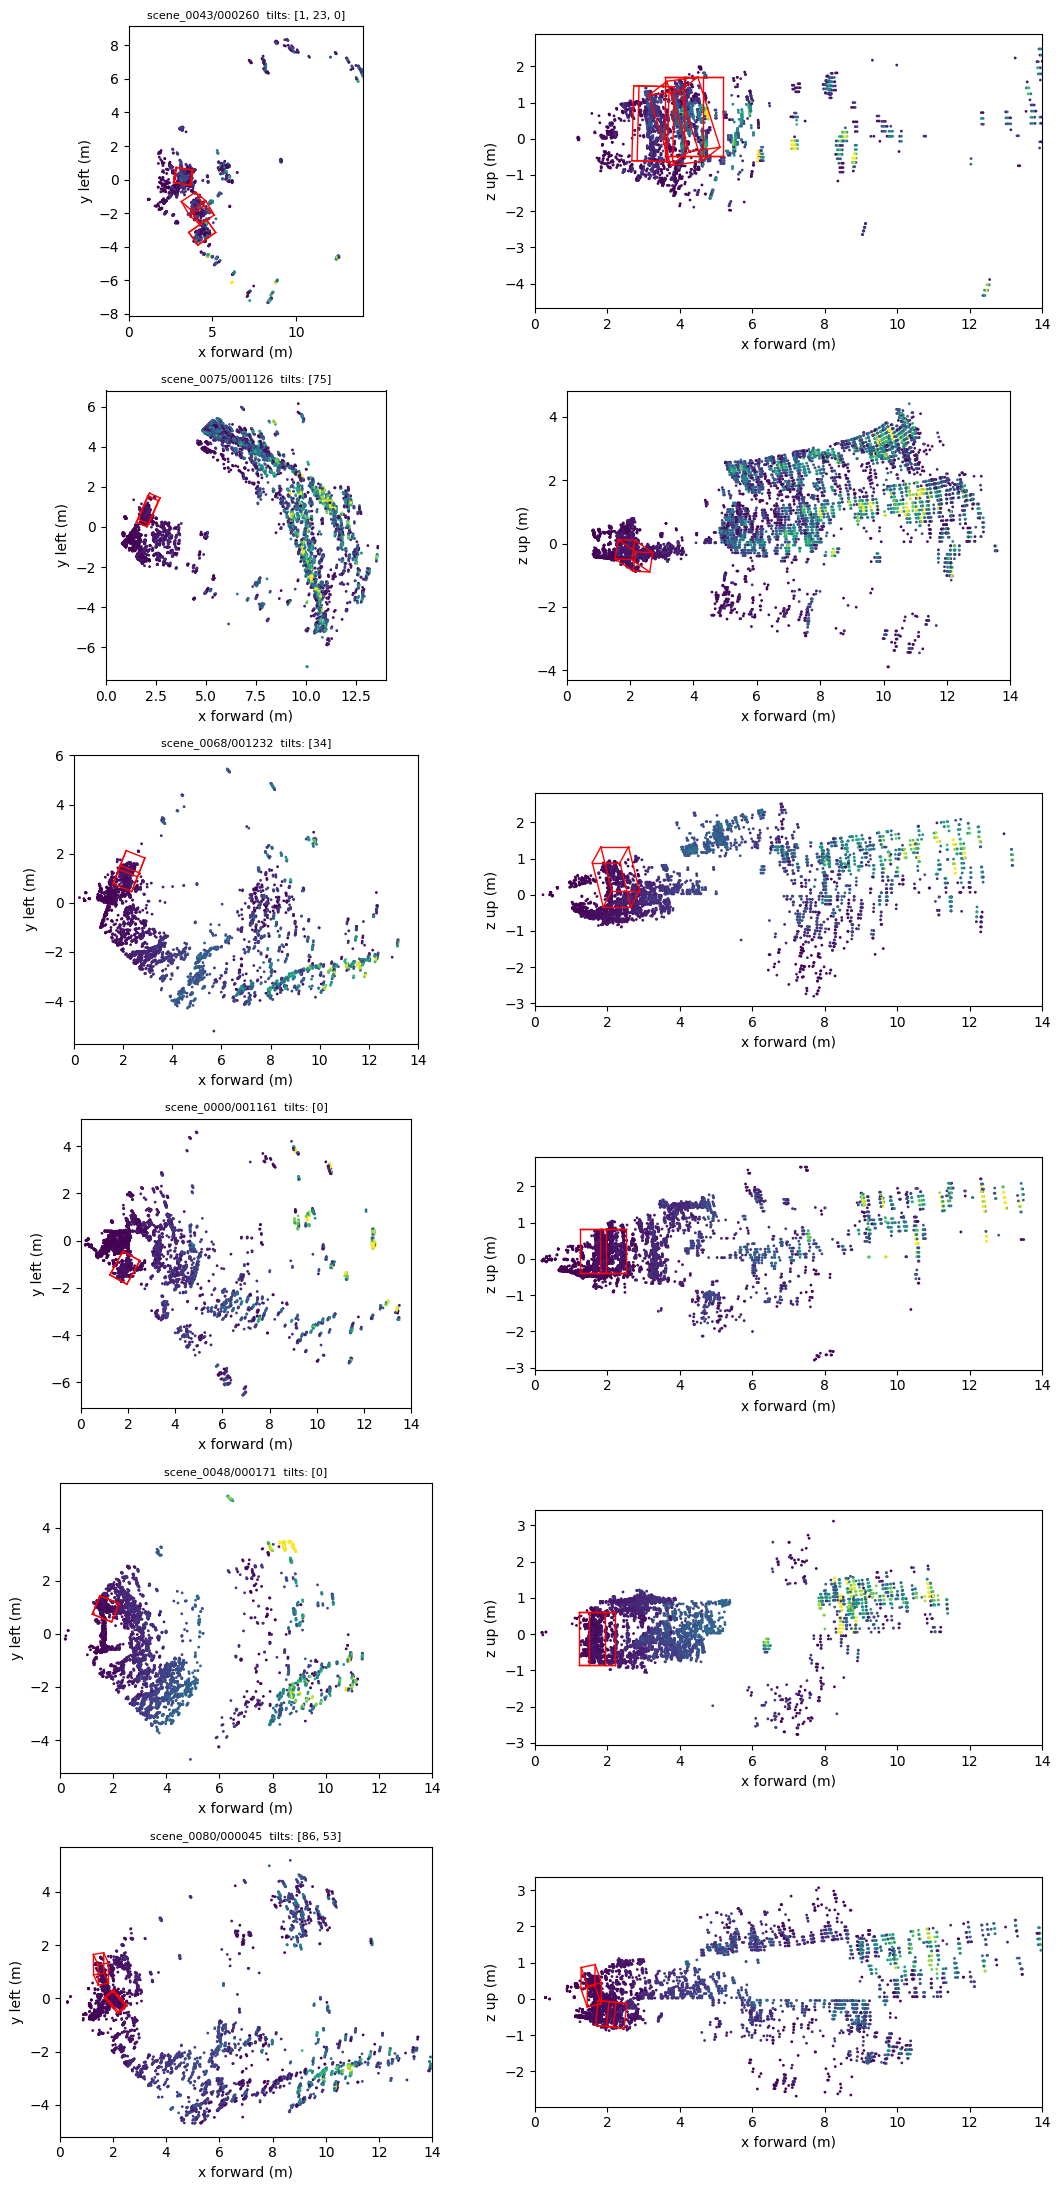

In [29]:
import random, os
import matplotlib.pyplot as plt
os.makedirs("/kaggle/working/viz", exist_ok=True)

def draw_frame(ax_top, ax_side, token, gt):
    pts = load_bin(frame_path(token))
    ax_top.scatter(pts[:,0], pts[:,1], c=pts[:,3], s=1, cmap="viridis")
    ax_side.scatter(pts[:,0], pts[:,2], c=pts[:,3], s=1, cmap="viridis")
    tilts = []
    for b in gt[token]:
        R = quat_to_rotmat(b["quaternion"])
        C = box_corners(b["center"], b["dimensions"], R)
        tilts.append(tilt_deg(R))
        for i, j in EDGES:
            ax_top.plot(C[[i,j],0], C[[i,j],1], c="r", lw=1)
            ax_side.plot(C[[i,j],0], C[[i,j],2], c="r", lw=1)
    ax_top.set_title(f"{token}  tilts: {[round(t) for t in tilts]}", fontsize=8)
    ax_top.set_xlabel("x forward (m)"); ax_top.set_ylabel("y left (m)")
    ax_side.set_xlabel("x forward (m)"); ax_side.set_ylabel("z up (m)")
    for a in (ax_top, ax_side):
        a.set_xlim(0, 14); a.set_aspect("equal")

random.seed(3)
with_diver = [t for t, bs in gt_val.items() if len(bs) > 0]
picks = random.sample(with_diver, 6)

fig, axes = plt.subplots(6, 2, figsize=(11, 22))
for row, tok in enumerate(picks):
    draw_frame(axes[row, 0], axes[row, 1], tok, gt_val)
plt.tight_layout()
plt.savefig("/kaggle/working/viz/gallery.png", dpi=110)
plt.show()

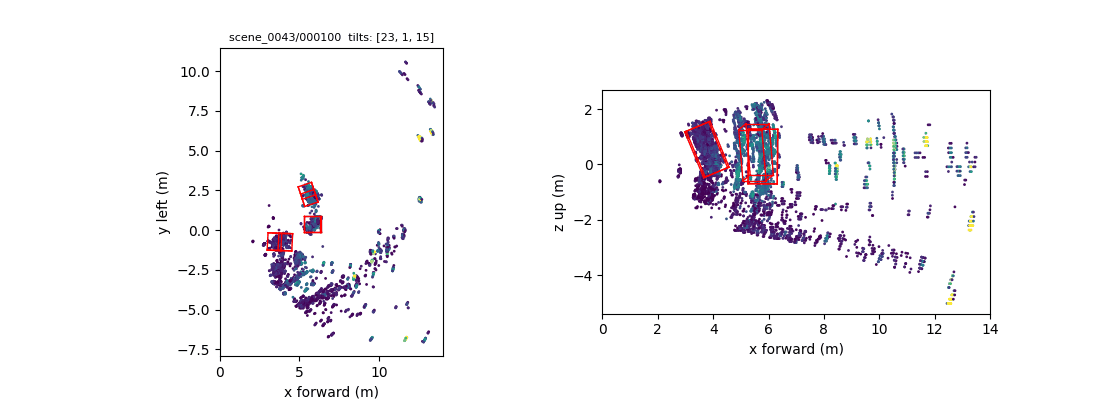

In [30]:
import matplotlib.animation as animation
scene = "scene_0043"
toks = sorted([t for t in gt_val if t.startswith(scene)])[100:160]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
def update(k):
    a1.clear(); a2.clear()
    draw_frame(a1, a2, toks[k], gt_val)
ani = animation.FuncAnimation(fig, update, frames=len(toks), interval=150)
ani.save("/kaggle/working/viz/scene.gif", writer="pillow")
plt.close(fig)
from IPython.display import Image
Image("/kaggle/working/viz/scene.gif")

In [31]:
import random, numpy as np
random.seed(1)

def inside_count(pts, c, d, R):
    local = (pts[:, :3] - np.asarray(c)) @ R   # body-frame coordinates
    return int(np.all(np.abs(local) <= np.asarray(d) / 2, axis=1).sum())

inst = [(tok, b) for tok, bs in gt_train.items() for b in bs]
sample = random.sample(inst, 1000)

counts, dists, heights = [], [], []
for tok, b in sample:
    pts = load_bin(frame_path(tok))
    counts.append(inside_count(pts, b["center"], b["dimensions"], quat_to_rotmat(b["quaternion"])))
    dists.append(b["center"][0]); heights.append(b["dimensions"][2])

pc = [5, 25, 50, 75, 95]
print("points inside a real diver box (5/25/50/75/95%):", np.percentile(counts, pc).astype(int))
print("diver distance x in m          (5/25/50/75/95%):", np.round(np.percentile(dists, pc), 1))
print("diver height in m              (5/25/50/75/95%):", np.round(np.percentile(heights, pc), 2))
print(f"divers with < 80 points inside: {100*np.mean(np.array(counts) < 80):.0f}%")

points inside a real diver box (5/25/50/75/95%): [ 298  543  793 1131 1770]
diver distance x in m          (5/25/50/75/95%): [1.6 2.3 2.9 3.6 5.1]
diver height in m              (5/25/50/75/95%): [1.   1.53 1.76 1.92 2.16]
divers with < 80 points inside: 0%


In [32]:
import torch
from torch.utils.data import Dataset, DataLoader

XR, YR, ZR, CELL = (0.0, 12.0), (-5.0, 5.0), (-2.5, 2.5), 0.25
NX, NY = int((XR[1]-XR[0])/CELL), int((YR[1]-YR[0])/CELL)   # 48 x 40
SIGMA = 1.5                                                  # heatmap blob size in cells
gx, gy = np.meshgrid(np.arange(NX), np.arange(NY), indexing="ij")

def crop_points(pts):
    m = ((pts[:,0] >= XR[0]) & (pts[:,0] < XR[1]) &
         (pts[:,1] >= YR[0]) & (pts[:,1] < YR[1]) &
         (pts[:,2] >= ZR[0]) & (pts[:,2] < ZR[1]))
    return pts[m]

def build_targets(boxes):
    hm  = np.zeros((1, NX, NY), np.float32)
    reg = np.zeros((12, NX, NY), np.float32)   # dx,dy,z, logL,logW,logH, rot6d(6)
    msk = np.zeros((NX, NY), np.float32)
    for b in boxes:
        c = np.array(b["center"])
        fx, fy = (c[0]-XR[0])/CELL, (c[1]-YR[0])/CELL
        ix, iy = int(fx), int(fy)
        if not (0 <= ix < NX and 0 <= iy < NY) or not (ZR[0] <= c[2] < ZR[1]):
            continue                                        # ~0.1% of divers fall outside the crop
        g = np.exp(-((gx-ix)**2 + (gy-iy)**2) / (2*SIGMA**2))
        hm[0] = np.maximum(hm[0], g)
        hm[0, ix, iy] = 1.0
        R = quat_to_rotmat(b["quaternion"])
        reg[:, ix, iy] = np.concatenate([
            [fx-ix, fy-iy, c[2]], np.log(b["dimensions"]), R[:,0], R[:,1]])
        msk[ix, iy] = 1.0
    return hm, reg, msk

class DiverDataset(Dataset):
    def __init__(self, gt, tokens=None, max_pts=8192):
        self.gt = gt
        self.tokens = tokens if tokens is not None else list(gt.keys())
        self.max_pts = max_pts
    def __len__(self): return len(self.tokens)
    def __getitem__(self, i):
        tok = self.tokens[i]
        pts = crop_points(load_bin(frame_path(tok)))
        if len(pts) > self.max_pts:
            pts = pts[np.random.choice(len(pts), self.max_pts, replace=False)]
        hm, reg, msk = build_targets(self.gt[tok])
        return dict(token=tok, pts=torch.from_numpy(pts), hm=torch.from_numpy(hm),
                    reg=torch.from_numpy(reg), msk=torch.from_numpy(msk))

def collate(batch):
    n = max(len(b["pts"]) for b in batch)
    pts  = torch.zeros(len(batch), n, 4)
    pmsk = torch.zeros(len(batch), n, dtype=torch.bool)
    for k, b in enumerate(batch):
        pts[k, :len(b["pts"])] = b["pts"]; pmsk[k, :len(b["pts"])] = True
    return dict(token=[b["token"] for b in batch], pts=pts, pmsk=pmsk,
                hm=torch.stack([b["hm"] for b in batch]),
                reg=torch.stack([b["reg"] for b in batch]),
                msk=torch.stack([b["msk"] for b in batch]))

train_ds = DiverDataset(gt_train)
val_ds   = DiverDataset(gt_val)
train_dl = DataLoader(train_ds, batch_size=8, shuffle=True,  num_workers=2, collate_fn=collate)
val_dl   = DataLoader(val_ds,   batch_size=8, shuffle=False, num_workers=2, collate_fn=collate)
print(len(train_ds), "train |", len(val_ds), "val |", torch.cuda.is_available() and torch.cuda.get_device_name(0))

20861 train | 8037 val | Tesla T4


pts (8, 8192, 4)
pmsk (8, 8192)
hm (8, 1, 48, 40)
reg (8, 12, 48, 40)
msk (8, 48, 40)
max rotation round-trip error: 3.629935149684904e-08 (should be ~1e-6)


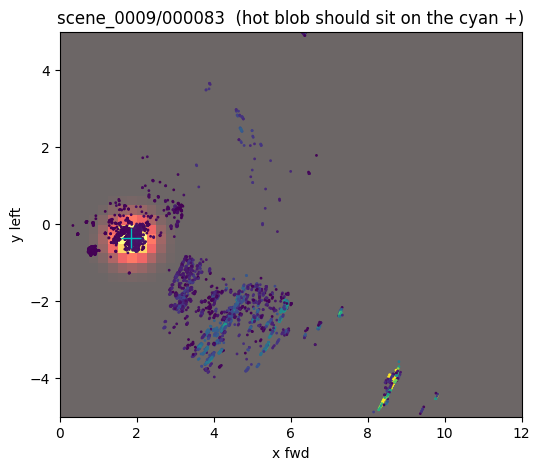

In [33]:
import matplotlib.pyplot as plt

def rot6d_to_R(r6):                       # Gram-Schmidt, columns ex, ey, ez
    a, b = np.asarray(r6[:3], float), np.asarray(r6[3:], float)
    ex = a / np.linalg.norm(a)
    ey = b - ex*(ex @ b); ey /= np.linalg.norm(ey)
    return np.stack([ex, ey, np.cross(ex, ey)], 1)

# 1) shapes
batch = next(iter(train_dl))
for k in ("pts", "pmsk", "hm", "reg", "msk"): print(k, tuple(batch[k].shape))

# 2) rotation round trip: GT quaternion -> 6D target -> matrix, should match
errs = []
for tok, bs in list(gt_train.items())[:3000]:
    if not bs: continue
    hm, reg, msk = build_targets(bs)
    for ix, iy in zip(*np.nonzero(msk)):
        R2 = rot6d_to_R(reg[6:12, ix, iy])
        errs.append(min(np.abs(R2 - quat_to_rotmat(b["quaternion"])).max() for b in bs))
print("max rotation round-trip error:", np.max(errs), "(should be ~1e-6)")

# 3) heatmap vs real points on a frame with a diver
tok = next(t for t, bs in gt_train.items() if len(bs) > 0)
item = train_ds[train_ds.tokens.index(tok)]
fig, ax = plt.subplots(figsize=(9, 5))
ax.imshow(item["hm"][0].numpy().T, origin="lower", extent=[XR[0], XR[1], YR[0], YR[1]], cmap="hot", alpha=0.6)
p = item["pts"].numpy()
ax.scatter(p[:,0], p[:,1], c=p[:,3], s=1, cmap="viridis")
for b in gt_train[tok]: ax.plot(b["center"][0], b["center"][1], "c+", ms=15)
ax.set_title(tok + "  (hot blob should sit on the cyan +)"); ax.set_xlabel("x fwd"); ax.set_ylabel("y left")
plt.show()

In [34]:
import torch.nn as nn, torch.nn.functional as F

class PillarEncoder(nn.Module):
    def __init__(self, c=64):
        super().__init__()
        self.c = c
        self.mlp = nn.Sequential(nn.Linear(6, 32), nn.ReLU(), nn.Linear(32, c), nn.ReLU())
    def forward(self, pts, pmsk):
        B, N, _ = pts.shape
        ix = ((pts[..., 0] - XR[0]) / CELL).floor().long().clamp(0, NX - 1)
        iy = ((pts[..., 1] - YR[0]) / CELL).floor().long().clamp(0, NY - 1)
        dx = pts[..., 0] - (XR[0] + (ix.float() + 0.5) * CELL)
        dy = pts[..., 1] - (YR[0] + (iy.float() + 0.5) * CELL)
        f = self.mlp(torch.cat([pts, dx[..., None], dy[..., None]], -1))   # B,N,c
        cell = torch.where(pmsk, ix * NY + iy, torch.full_like(ix, NX * NY))  # padding -> dummy cell
        out = f.new_zeros(B, NX * NY + 1, self.c)
        out.scatter_reduce_(1, cell[..., None].expand(-1, -1, self.c), f,
                            reduce="amax", include_self=False)
        cnt = f.new_zeros(B, NX * NY + 1)
        cnt.scatter_add_(1, cell, pmsk.float())
        out = torch.cat([out, torch.log1p(cnt)[..., None]], -1)[:, :NX * NY]
        return out.view(B, NX, NY, self.c + 1).permute(0, 3, 1, 2).contiguous()

def cbr(i, o, s=1):
    return nn.Sequential(nn.Conv2d(i, o, 3, s, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

class DiverNet(nn.Module):
    # output channels: 1 heatmap + 3 (dx,dy,z) + 3 log-size + 6 rotation = 13
    def __init__(self, c=64):
        super().__init__()
        self.enc = PillarEncoder(c)
        self.b1 = nn.Sequential(cbr(c + 1, 64), cbr(64, 64))
        self.b2 = nn.Sequential(cbr(64, 128, 2), cbr(128, 128))
        self.b3 = nn.Sequential(cbr(128, 256, 2), cbr(256, 256))
        self.fuse = nn.Sequential(cbr(64 + 128 + 256, 128), cbr(128, 128))
        self.head = nn.Sequential(cbr(128, 64), nn.Conv2d(64, 13, 1))
        nn.init.zeros_(self.head[-1].bias)
        self.head[-1].bias.data[0] = -2.19          # start with "mostly empty" heatmap
    def forward(self, pts, pmsk):
        x1 = self.b1(self.enc(pts, pmsk)); x2 = self.b2(x1); x3 = self.b3(x2)
        up = lambda t: F.interpolate(t, size=x1.shape[-2:], mode="bilinear", align_corners=False)
        return self.head(self.fuse(torch.cat([x1, up(x2), up(x3)], 1)))

dev = "cuda"
model = DiverNet().to(dev)
print(sum(p.numel() for p in model.parameters()) / 1e6, "M parameters")
b = next(iter(train_dl))
print("output:", tuple(model(b["pts"].to(dev), b["pmsk"].to(dev)).shape), "(expect 8, 13, 48, 40)")

1.923117 M parameters
output: (8, 13, 48, 40) (expect 8, 13, 48, 40)


In [39]:
def focal_loss(logits, gt):
    p = logits.float().sigmoid().clamp(1e-4, 1 - 1e-4)
    pos = gt.eq(1).float()
    pos_l = -(torch.log(p) * (1 - p) ** 2 * pos).sum()
    neg_l = -(torch.log(1 - p) * p ** 2 * (1 - gt) ** 4 * (1 - pos)).sum()
    return (pos_l + neg_l) / pos.sum().clamp(min=1)

def sixd_to_R(r):                                   # (K,6) -> (K,3,3), columns ex, ey, ez
    ex = F.normalize(r[:, :3], dim=1)
    b = r[:, 3:]
    ey = F.normalize(b - (ex * b).sum(1, keepdim=True) * ex, dim=1)
    return torch.stack([ex, ey, torch.cross(ex, ey, dim=1)], dim=2)

FLIP = torch.diag(torch.tensor([-1., -1., 1.]))     # 180 deg about the body's own long axis
def rot_loss(pred6, tgt6):
    Rp, Rg = sixd_to_R(pred6), sixd_to_R(tgt6)
    flip = FLIP.to(Rg)
    def ang(R2):
        tr = (Rp.transpose(1, 2) @ R2).diagonal(dim1=1, dim2=2).sum(-1)
        return torch.acos(((tr - 1) / 2).clamp(-1 + 1e-6, 1 - 1e-6))
    return torch.minimum(ang(Rg), ang(Rg @ flip))

def compute_loss(out, hm, reg, msk):
    l_hm = focal_loss(out[:, :1], hm)
    m = msk.bool()
    if m.any():
        po = out[:, 1:].permute(0, 2, 3, 1)[m]
        to = reg.permute(0, 2, 3, 1)[m]
        l_box = F.l1_loss(po[:, :6], to[:, :6])
        l_rot = rot_loss(po[:, 6:], to[:, 6:]).mean()
    else:
        l_box = l_rot = out.sum() * 0
    return l_hm + l_box + l_rot, dict(hm=l_hm.item(), box=l_box.item(), rot_deg=np.degrees(l_rot.item()))

@torch.no_grad()
def decode(out, tokens, K=10, thr=0.02):
    hm = out[:, 0].sigmoid()
    peak = hm * (hm == F.max_pool2d(hm[:, None], 3, 1, 1)[:, 0]).float()   # keep local maxima only
    res = {}
    for b, tok in enumerate(tokens):
        sc, idx = peak[b].flatten().topk(K)
        dets = []
        for s, i in zip(sc.tolist(), idx.tolist()):
            if s < thr: break
            ix, iy = divmod(i, NY)
            p = out[b, 1:, ix, iy]
            R = sixd_to_R(p[None, 6:])[0].cpu().numpy()
            dets.append({"center": [XR[0] + (ix + float(p[0])) * CELL,
                                    YR[0] + (iy + float(p[1])) * CELL, float(p[2])],
                         "dimensions": np.exp(p[3:6].cpu().numpy()).tolist(),
                         "rotation_matrix": R.tolist(), "score": float(s)})
        res[tok] = dets
    return res

In [40]:
import time

def train(model, epochs, max_iters=None, lr=2e-3):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    total = min(len(train_dl) * epochs, max_iters or 10**9)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=total)
    it, t0 = 0, time.time()
    for ep in range(epochs):
        model.train()
        for b in train_dl:
            out = model(b["pts"].to(dev), b["pmsk"].to(dev))
            loss, parts = compute_loss(out, b["hm"].to(dev), b["reg"].to(dev), b["msk"].to(dev))
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
            opt.step(); sched.step(); it += 1
            if it % 50 == 0:
                print(f"it {it}/{total}  loss {loss.item():.3f}  hm {parts['hm']:.3f}  "
                      f"box {parts['box']:.3f}  rot {parts['rot_deg']:.1f} deg  ({time.time()-t0:.0f}s)")
            if it >= total: break
        torch.save(model.state_dict(), "/content/ckpt.pt")
        if it >= total: break

@torch.no_grad()
def predict(model, tokens):
    model.eval()
    dl = DataLoader(DiverDataset(gt_val, tokens), batch_size=16, shuffle=False,
                    num_workers=2, collate_fn=collate)
    res = {}
    for b in dl:
        out = model(b["pts"].to(dev), b["pmsk"].to(dev))
        res.update(decode(out, b["token"]))
    return res

def score_subset(model, name):
    sub_tokens = list(gt_val.keys())[::10]          # same 804-frame subset as the baseline
    res = predict(model, sub_tokens)
    json.dump({"results": res}, open(f"/content/pred_{name}.json", "w"))
    print("avg detections/frame:", np.mean([len(v) for v in res.values()]))
    !python {ROOT}/tools/diver3d_eval.py --gt /content/gt_val_sub.json --pred /content/pred_{name}.json

# step 1: smoke test
train(model, epochs=1, max_iters=200)

it 50/200  loss 3.250  hm 1.438  box 0.369  rot 82.7 deg  (3s)
it 100/200  loss 2.783  hm 1.346  box 0.230  rot 69.2 deg  (4s)
it 150/200  loss 2.118  hm 0.744  box 0.208  rot 66.8 deg  (6s)
it 200/200  loss 1.717  hm 0.589  box 0.218  rot 52.1 deg  (7s)


In [41]:
import subprocess

def score_subset(model, name):
    sub_tokens = list(gt_val.keys())[::10]          # same 804-frame subset as the baseline
    res = predict(model, sub_tokens)
    json.dump({"results": res}, open(f"/content/pred_{name}.json", "w"))
    print("avg detections/frame:", np.mean([len(v) for v in res.values()]))
    out = subprocess.run(["python", f"{ROOT}/tools/diver3d_eval.py",
                          "--gt", "/content/gt_val_sub.json",
                          "--pred", f"/content/pred_{name}.json"],
                         capture_output=True, text=True)
    print(out.stdout[-1500:], out.stderr[-500:])

In [42]:
model = DiverNet().to(dev)
print(f"{sum(p.numel() for p in model.parameters())/1e6:.2f} M parameters")
train(model, epochs=3)
score_subset(model, "so3_3ep")

1.92 M parameters
it 50/7824  loss 2.710  hm 1.181  box 0.309  rot 69.9 deg  (2s)
it 100/7824  loss 2.086  hm 1.133  box 0.196  rot 43.4 deg  (3s)
it 150/7824  loss 2.235  hm 0.782  box 0.287  rot 66.8 deg  (5s)
it 200/7824  loss 2.176  hm 0.794  box 0.249  rot 65.0 deg  (6s)
it 250/7824  loss 2.730  hm 1.445  box 0.243  rot 59.6 deg  (8s)
it 300/7824  loss 2.566  hm 1.126  box 0.298  rot 65.4 deg  (9s)
it 350/7824  loss 1.964  hm 0.973  box 0.244  rot 42.9 deg  (11s)
it 400/7824  loss 2.030  hm 0.815  box 0.265  rot 54.4 deg  (12s)
it 450/7824  loss 2.904  hm 1.186  box 0.253  rot 83.9 deg  (14s)
it 500/7824  loss 2.164  hm 0.891  box 0.214  rot 60.6 deg  (15s)
it 550/7824  loss 1.748  hm 0.587  box 0.249  rot 52.3 deg  (17s)
it 600/7824  loss 3.331  hm 1.207  box 0.230  rot 108.5 deg  (18s)
it 650/7824  loss 1.102  hm 0.272  box 0.242  rot 33.7 deg  (20s)
it 700/7824  loss 2.119  hm 1.048  box 0.292  rot 44.6 deg  (21s)
it 750/7824  loss 2.013  hm 0.816  box 0.196  rot 57.4 deg  (23s